In [1]:
from pathlib import Path
import sys

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
project_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "sw" / "lib" / "vco_lut.py").exists()
)

sys.path.insert(0, str(project_root))

In [4]:
from sw.lib.vco_lut import *
from sw.lib.pll_settings import *

Plotting traces function

In [5]:
def plot_spectrum_traces(csv_filepath: str):
    """
    Reads a long-format CSV generated by sweep_grid_averaged_trace 
    and plots the spectrum traces for each configuration.
    """
    print(f"Loading data from {csv_filepath}...")
    df = pd.read_csv(csv_filepath)

    # Filter out rows where instrument connection failed
    df = df[df['level_dbm'] != 'ERROR'].copy()

    # Ensure measurement columns are numeric
    df['freq_hz'] = pd.to_numeric(df['freq_hz'])
    df['level_dbm'] = pd.to_numeric(df['level_dbm'])

    # Group by the configuration parameters to isolate individual traces
    group_cols = ['cfg_idx', 'set_current', 'set_c1', 'set_c2', 'set_r1']
    
    plt.figure(figsize=(12, 7))

    for name, group in df.groupby(group_cols):
        cfg_idx, curr, c1, c2, r1 = name
        label = f"Base {cfg_idx} | Curr:{curr} C1:{c1} C2:{c2} R1:{r1}"
        
        # Sort by frequency to ensure the line plots sequentially
        group = group.sort_values('freq_hz')
        
        # Scale frequency to MHz for a cleaner X-axis
        plt.plot(group['freq_hz'] / 1e6, group['level_dbm'], label=label, linewidth=1.5)

    plt.title('PLL Averaged Spectrum Traces')
    plt.xlabel('Frequency (MHz)')
    plt.ylabel('Power Level (dBm)')
    plt.grid(True, which="both", linestyle="--", alpha=0.6)
    
    # Place legend outside the plot area to avoid covering the traces
    plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize='small')
    plt.tight_layout()
    plt.show()

### VCO LUT instantiation

In [6]:
lut = VcoLUT(sample="S5")

### Operating point of the `CFG_COARSE0_FAST`

In [7]:
operating_point = lut.predict(CFG_COARSE0_FAST, f_vco=4.8e9)

In [8]:
print(operating_point)

{'vctrl_pred': 0.5138661654927704, 'kvco_pred': 30462113279.999973}


## Search for the optimal config

### Config that locks at $f_{ref} = 75 MHz$

In [9]:
cfg_lock_75 = lut.update_config(DEFAULT_CFG, f_vco=8e9, kvco=10e9)

In [10]:
op_cfg_lock_75 = lut.predict(cfg_lock_75, f_vco=9.6e9)
print(op_cfg_lock_75)

{'vctrl_pred': 0.47053826994881454, 'kvco_pred': 32317069824.000023}


In [11]:
for key, value in cfg_lock_75.items():
    print(f"{key:20} : {value}")

fb_clk_oen           : 1
pll_clk_o_en         : 0
clk_div_val          : 4
clk_div_en           : 1
pdown_PD             : 0
pdown_VCO            : 0
set_current          : 3
set_c1               : 3
set_c2               : 3
set_r1               : 3
vco_tune_coarse      : 0
vco_current_min      : 0
vco_current_max      : 2
set_v_ctrl           : 2
set_clk_out          : 0
set_div_freq         : 2
set_fb_mux           : 0


In [12]:
CSV_DIR = Path.cwd().resolve().parents[2] / "results" / "spectrum"  # notebook lives in sw/tools/notebooks/
TRACES_OPT_CSV = "averaged_trace_grid_20261008_153046.csv"
filepath = CSV_DIR / TRACES_OPT_CSV

#### **$R_1$** Variation

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261008_153046.csv...


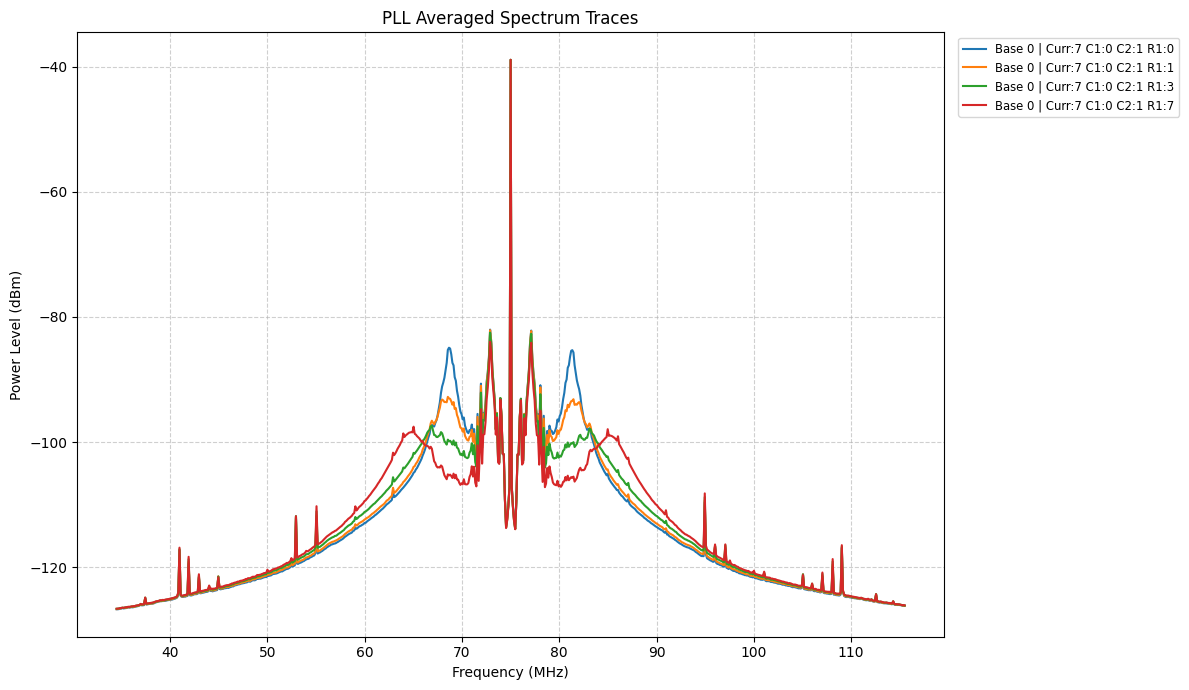

In [13]:
plot_spectrum_traces(filepath)

#### $C_1$ Variation

In [14]:
TRACES_OPT_CSV = "averaged_trace_grid_20261008_154623.csv"
filepath = CSV_DIR / TRACES_OPT_CSV

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261008_154623.csv...


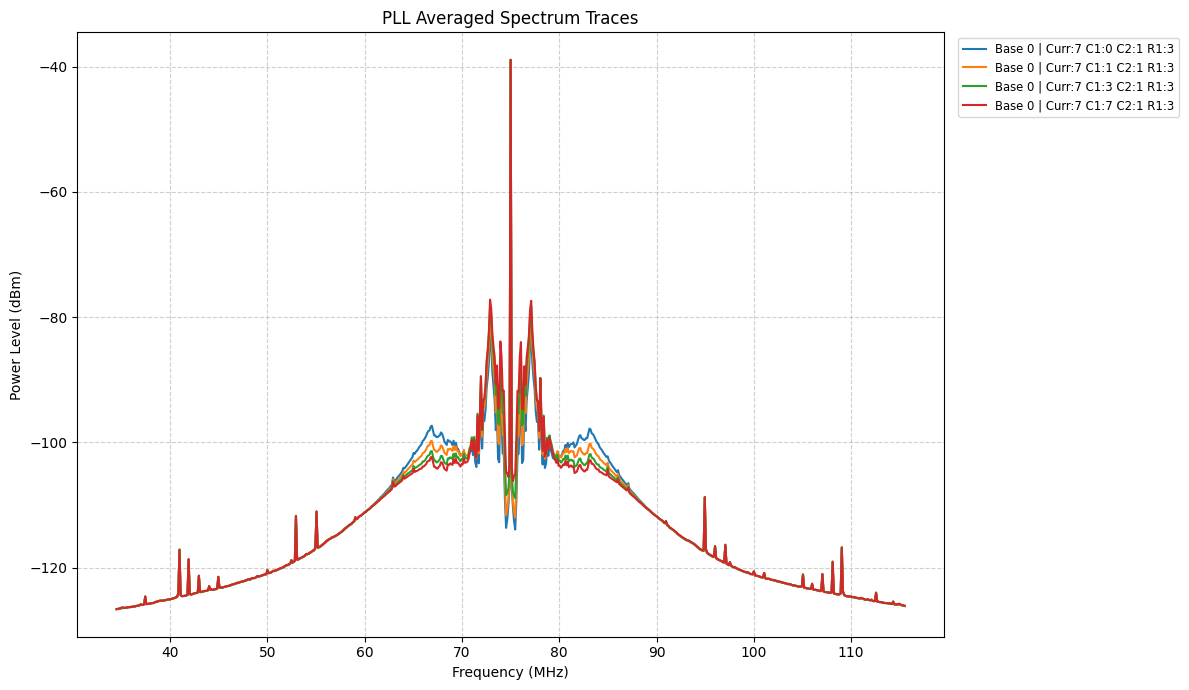

In [15]:
plot_spectrum_traces(filepath)

#### $C_2$ Variation

In [16]:
TRACES_OPT_CSV = "averaged_trace_grid_20261008_155712.csv"
filepath = CSV_DIR / TRACES_OPT_CSV

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261008_155712.csv...


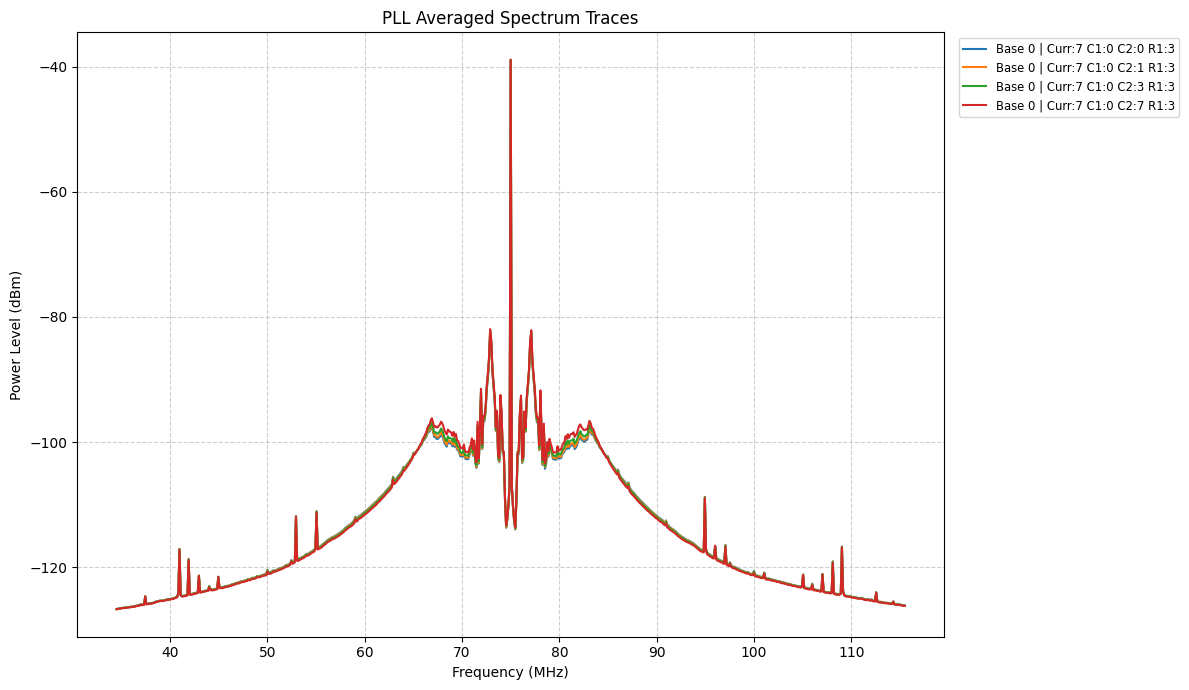

In [17]:
plot_spectrum_traces(filepath)

#### $I_{CP}$ Variation

In [18]:
TRACES_OPT_CSV = "averaged_trace_grid_20261008_160532.csv"
filepath = CSV_DIR / TRACES_OPT_CSV

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261008_160532.csv...


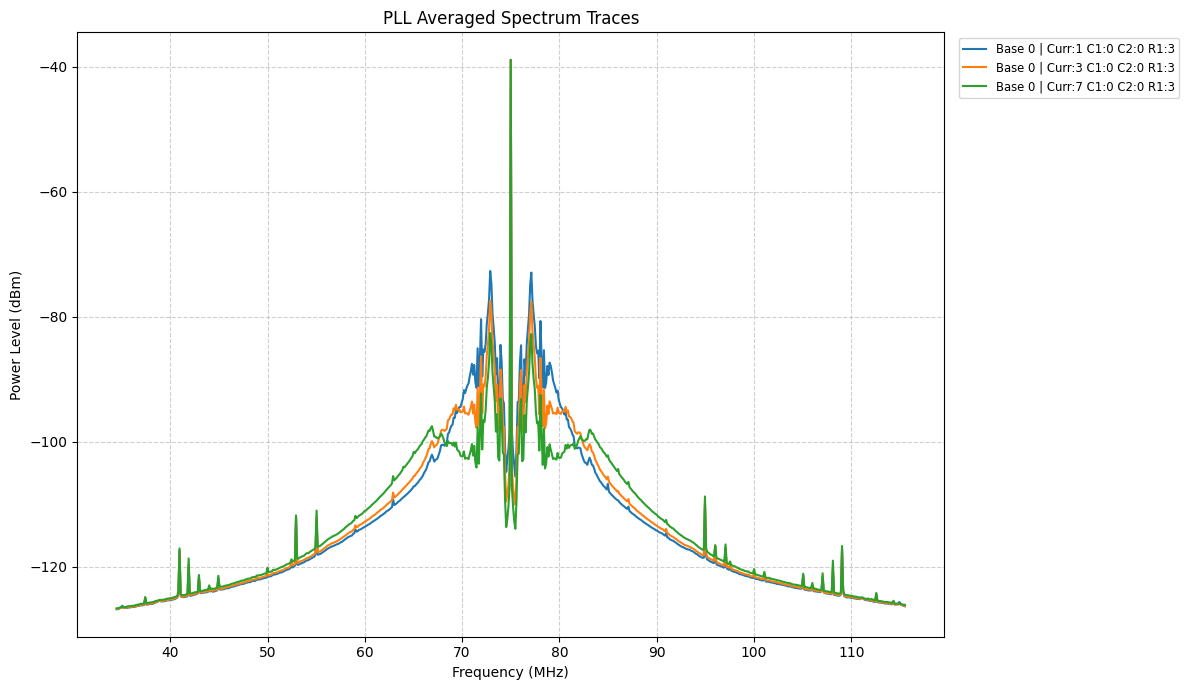

In [19]:
plot_spectrum_traces(filepath)